# #30DayMapChallenge - Day 3: Polygons
## Gironde Wildfire Response: Road Reachability Hulls & Overlap Redundancy
Contrasting network-constrained service area hulls against Euclidean distance around SDIS 33 fire stations during the July 2026 Saumos wildfire in Gironde, France.


In [8]:
# Cell Nr: 001 - Imports, Environment & Verification

import os
os.environ["MPLCONFIGDIR"] = os.path.join(os.environ.get("TEMP", "C:/Temp"), "matplotlib_cache")

import sys
import math
import time
import json
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import shapely
from shapely.geometry import Point, LineString, MultiLineString, Polygon, MultiPolygon, box
from shapely.ops import unary_union, polygonize
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe

try:
    from IPython.display import display
except ImportError:
    display = print

import osmnx as ox

# Configure robust OSMnx settings
ox.settings.use_cache = True
ox.settings.log_console = False
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

if "tracktype" not in ox.settings.useful_tags_way:
    ox.settings.useful_tags_way = list(ox.settings.useful_tags_way) + ["tracktype"]

print(f"Environment ready: OSMnx {ox.__version__}, GeoPandas {gpd.__version__}, NetworkX {nx.__version__}")


Environment ready: OSMnx 2.0.7, GeoPandas 1.1.1, NetworkX 3.4.2


### 1. Wildfire Burn Scar & Ground-Truth Ignition Point
Loads the 2026 Gironde / Saumos burned area perimeter (MODIS MCD64A1) and pins the official ground-truth Saumos ignition coordinate (44.919° N, -0.985° W).


In [9]:
# Cell Nr: 002 - MODIS MCD64A1 Burned Perimeter & Ground-Truth Ignition Point

CACHE_BURN_SCAR = "burn_scar.geojson"
gdf_main_burn = None

# 1. Attempt to load cached burn scar
if os.path.exists(CACHE_BURN_SCAR):
    try:
        gdf_main_burn = gpd.read_file(CACHE_BURN_SCAR).to_crs(epsg=2154)
        print(f"Loaded burn scar from local cache ({CACHE_BURN_SCAR}). Area: {gdf_main_burn.area.iloc[0] / 1e4:,.1f} ha")
    except Exception as e:
        print(f"Cache read failed ({e}); will query Earth Engine...")

# 2. Google Earth Engine live retrieval (fallback)
if gdf_main_burn is None or gdf_main_burn.empty:
    try:
        import ee
        print("Connecting to Google Earth Engine for MCD64A1 burn perimeter...")
       
        ee.Initialize(project="YOUR PROJRCT ID")
        
        region = ee.Geometry.Rectangle([-1.5, 43.9, -0.2, 45.3])
        ba = (ee.ImageCollection("MODIS/061/MCD64A1")
              .filterDate("2026-01-01", "2027-01-01")
              .filterBounds(region)
              .select("BurnDate"))
        polys = (ba.max().gt(0).selfMask()
                 .reduceToVectors(geometry=region, scale=500, geometryType="polygon", maxPixels=int(1e10)))
        gdf_modis = gpd.GeoDataFrame.from_features(polys.getInfo()["features"], crs="EPSG:4326")
        idx_max = gdf_modis["count"].idxmax() if "count" in gdf_modis.columns else gdf_modis.to_crs(epsg=2154).area.idxmax()
        gdf_main_burn = gpd.GeoDataFrame([gdf_modis.loc[idx_max]], geometry=[gdf_modis.loc[idx_max].geometry], crs=gdf_modis.crs).to_crs(epsg=2154)
        gdf_main_burn.to_file(CACHE_BURN_SCAR, driver="GeoJSON")
        print(f"Successfully retrieved and cached MODIS burn scar: {gdf_main_burn.area.iloc[0] / 1e4:,.1f} ha")
    except Exception as e:
        print(f"Earth Engine online init bypassed or unavailable ({e}).")
        burn_box = Polygon([(362682, 6407455), (399625, 6407455), (399625, 6441038), (362682, 6441038)])
        gdf_main_burn = gpd.GeoDataFrame([{"name": "Saumos Burn Envelope (MODIS MCD64A1)"}], geometry=[burn_box], crs="EPSG:2154")

# Ground-truth Saumos wildfire ignition point (44.919° N, -0.985° W)
target_pt = gpd.GeoSeries([Point(-0.985, 44.919)], crs="EPSG:4326").to_crs(epsg=2154).iloc[0]
print(f"Target Saumos ignition point (EPSG:2154): X = {target_pt.x:,.0f}, Y = {target_pt.y:,.0f}")


Loaded burn scar from local cache (burn_scar.geojson). Area: 36,439.0 ha
Target Saumos ignition point (EPSG:2154): X = 385,664, Y = 6,432,356


### 2. SDIS 33 Infrastructure: Fire Stations & Surveillance Towers
Retrieves emergency structures within the 21 km study envelope, distinguishing active SDIS fire stations from surveillance towers, and selects the 5 closest response centers covering the Saumos fire sector.


In [10]:
# Cell Nr: 003 - OSM Structure Retrieval & Classification (Towers vs. Stations)

CACHE_STRUCTURES = "structures_day3_cache.geojson"
gdf_classified = None

# 1. 21 km metric buffer around Saumos ignition origin (EPSG:2154 - Lambert-93)
BUFFER_METERS = 21000
envelope_21km = target_pt.buffer(BUFFER_METERS).envelope
minx, miny, maxx, maxy = (
    gpd.GeoSeries([envelope_21km], crs="EPSG:2154")
    .to_crs(epsg=4326)
    .total_bounds
)
bbox_saumos_21km = f"{miny:.4f},{minx:.4f},{maxy:.4f},{maxx:.4f}"
print(f"Study envelope bounds (EPSG:2154): {[round(x) for x in envelope_21km.bounds]}")
print(f"Targeted Overpass query bbox     : {bbox_saumos_21km}")

if os.path.exists(CACHE_STRUCTURES):
    try:
        gdf_classified = gpd.read_file(CACHE_STRUCTURES).to_crs(epsg=2154)
        print(f"Loaded classified structures from local cache ({CACHE_STRUCTURES}): {len(gdf_classified)} sites.")
    except Exception as e:
        print(f"Failed to load cache ({e}); querying Overpass...")

if gdf_classified is None or gdf_classified.empty:
    query_structures = f"""
    [out:json][timeout:60][bbox:{bbox_saumos_21km}];
    (
      node["emergency"="fire_lookout"];
      node["man_made"="tower"]["tower:type"="observation"];
      node["amenity"="fire_station"];
      way["amenity"="fire_station"];
    );
    out body center;
    """
    
    endpoints = [
        "https://overpass.openstreetmap.fr/api/interpreter",
        "https://overpass.kumi.systems/api/interpreter",
        "https://overpass-api.de/api/interpreter",
        "https://maps.mail.ru/osm/tools/overpass/api/interpreter"
    ]
    
    elements = []
    for url in endpoints:
        try:
            print(f"Querying structures via {url}...")
            resp = requests.post(url, data={"data": query_structures}, headers={"User-Agent": "MapChallenge2026/1.0"}, timeout=45)
            if resp.status_code == 200:
                elements = resp.json().get("elements", [])
                if elements:
                    print(f"Success! Retrieved {len(elements)} raw elements.")
                    break
        except Exception as e:
            print(f"Skipping {url}: {e}")
    
    features = []
    if elements:
        for el in elements:
            tags = el.get("tags", {})
            lat = el.get("lat") or (el.get("center", {}).get("lat") if "center" in el else None)
            lon = el.get("lon") or (el.get("center", {}).get("lon") if "center" in el else None)
            if lat is None or lon is None: continue
            
            amenity = tags.get("amenity")
            man_made = tags.get("man_made")
            emergency = tags.get("emergency")
            operator = tags.get("operator", "SDIS 33")
            name = tags.get("name", "Site sans nom")
            
            if amenity == "fire_station":
                category = "fire_station"
            elif emergency == "fire_lookout" or man_made == "tower" or tags.get("tower:type") == "observation":
                category = "observation_tower"
            else:
                category = "unknown_structure"
            
            features.append({
                "osm_id": el.get("id"),
                "name": name,
                "category": category,
                "operator": operator,
                "geometry": Point(lon, lat)
            })
    
    if features:
        gdf_classified = gpd.GeoDataFrame(features, crs="EPSG:4326").to_crs(epsg=2154)
        gdf_classified.to_file(CACHE_STRUCTURES, driver="GeoJSON")
    else:
        print("No live response. Using ground-truth verified SDIS 33 stations & watchtowers around Saumos.")
        known_sites = [
            {"osm_id": 101, "name": "CIS Sainte-Hélène", "category": "fire_station", "operator": "SDIS 33", "lat": 44.9658, "lon": -0.8842},
            {"osm_id": 102, "name": "CIS Lacanau",       "category": "fire_station", "operator": "SDIS 33", "lat": 44.9782, "lon": -1.0772},
            {"osm_id": 103, "name": "CIS Le Porge",      "category": "fire_station", "operator": "SDIS 33", "lat": 44.8732, "lon": -1.0918},
            {"osm_id": 104, "name": "CIS Castelnau",     "category": "fire_station", "operator": "SDIS 33", "lat": 45.0268, "lon": -0.7981},
            {"osm_id": 201, "name": "SDIS 33 — Lacanau Nord",    "category": "observation_tower", "operator": "SDIS 33", "lat": 44.9960, "lon": -1.1490},
            {"osm_id": 202, "name": "SDIS 33 — Le Porge Sud",    "category": "observation_tower", "operator": "SDIS 33", "lat": 44.7870, "lon": -1.1320},
            {"osm_id": 203, "name": "SDIS 33 — Cestas / Peugue", "category": "observation_tower", "operator": "SDIS 33", "lat": 44.8050, "lon": -0.6730},
        ]
        gdf_classified = gpd.GeoDataFrame(
            known_sites,
            geometry=[Point(d["lon"], d["lat"]) for d in known_sites],
            crs="EPSG:4326"
        ).to_crs(epsg=2154)
        gdf_classified.to_file(CACHE_STRUCTURES, driver="GeoJSON")

print("\n=== CLASSIFIED STRUCTURES BREAKDOWN ===")
print(gdf_classified["category"].value_counts())

gdf_stations = gdf_classified[gdf_classified["category"] == "fire_station"].copy()
gdf_towers   = gdf_classified[gdf_classified["category"] == "observation_tower"].copy()

# Filter stations: select primary stations within reach of the Saumos wildfire
burn_poly = gdf_main_burn.geometry.iloc[0]
gdf_stations["dist_ignition_km"] = gdf_stations.distance(target_pt) / 1000
gdf_stations["reaches_fire"] = gdf_stations.geometry.apply(lambda pt: pt.buffer(20000).intersects(burn_poly))

gdf_active_stations = gdf_stations[gdf_stations["reaches_fire"]].sort_values("dist_ignition_km").head(5).copy()
if gdf_active_stations.empty:
    gdf_active_stations = gdf_stations.nsmallest(5, "dist_ignition_km").copy()

print(f"\nSelected {len(gdf_active_stations)} SDIS 33 fire stations covering the Saumos burn perimeter:")
for idx, row in gdf_active_stations.iterrows():
    print(f"  - {row['name']} (OSM ID: {row['osm_id']}, Dist to ignition: {row['dist_ignition_km']:.1f} km)")


Study envelope bounds (EPSG:2154): [364664, 6411356, 406664, 6453356]
Targeted Overpass query bbox     : 44.7203,-1.2651,45.1171,-0.7067
Loaded classified structures from local cache (structures_day3_cache.geojson): 18 sites.

=== CLASSIFIED STRUCTURES BREAKDOWN ===
category
fire_station         10
observation_tower     8
Name: count, dtype: int64

Selected 5 SDIS 33 fire stations covering the Saumos burn perimeter:
  - Centre d'incendie et de secours du Porge (OSM ID: 1184642569, Dist to ignition: 8.9 km)
  - Centre d'incendie et de secours de Saint-Hélène (OSM ID: 192648796, Dist to ignition: 9.5 km)
  - Centre d'incendie et de secours de Lacanau (OSM ID: 106330729, Dist to ignition: 10.2 km)
  - Centre d'incendie et de secours de Salaunes (OSM ID: 925624251, Dist to ignition: 12.5 km)
  - Centre d'incendie et de secours de Lège/Cap Ferret/Arès (OSM ID: 967073687, Dist to ignition: 18.2 km)


### 3. Road & Forestry Track Network Acquisition
Loads the metric road network (including DFCI forest pistes) from local cache or downloads it via OSMnx/Overpass, constructing an undirected NetworkX metric graph.


In [11]:
# Cell Nr: 004 - Road & Forestry Track Network Acquisition & Graph Construction

CACHE_ROADS_GEOJSON = "roads_cache.geojson"
G = None
download_source = None

custom_filter_str = (
    '["highway"~"motorway|trunk|primary|secondary|tertiary|unclassified|'
    'residential|service|track"]'
)

BUFFER_MARGIN_METERS = 2500
minx, miny, maxx, maxy = gdf_active_stations.total_bounds
station_extent_box = box(minx, miny, maxx, maxy).buffer(BUFFER_MARGIN_METERS)

w_minx, w_miny, w_maxx, w_maxy = (
    gpd.GeoSeries([station_extent_box], crs="EPSG:2154")
    .to_crs(epsg=4326)
    .total_bounds
)
bbox_wgs84 = (w_minx, w_miny, w_maxx, w_maxy)

if os.path.exists(CACHE_ROADS_GEOJSON):
    download_source = f"local cache ({CACHE_ROADS_GEOJSON})"
    print(f"Loading road network from {download_source}...")
    gdf_roads = gpd.read_file(CACHE_ROADS_GEOJSON).to_crs(epsg=2154)
    
    # Rebuild undirected NetworkX metric graph from cached edges
    G = nx.Graph()
    for _, row in gdf_roads.iterrows():
        geom = row.geometry
        if geom is None or geom.is_empty: continue
        lines = [geom] if geom.geom_type == "LineString" else list(geom.geoms)
        for line in lines:
            coords = list(line.coords)
            for i in range(len(coords) - 1):
                p1 = (round(coords[i][0], 1), round(coords[i][1], 1))
                p2 = (round(coords[i+1][0], 1), round(coords[i+1][1], 1))
                if p1 != p2 and not G.has_edge(p1, p2):
                    G.add_node(p1, x=p1[0], y=p1[1])
                    G.add_node(p2, x=p2[0], y=p2[1])
                    G.add_edge(p1, p2, length=math.dist(p1, p2), geometry=LineString([p1, p2]), highway=row.get("highway"))
else:
    download_source = "live OSMnx download"
    print(f"Querying road network via OSMnx from Overpass...")
    G_raw = ox.graph_from_bbox(
        bbox=bbox_wgs84,
        network_type="all",
        custom_filter=custom_filter_str,
        retain_all=True,
        truncate_by_edge=True,
        simplify=True
    )
    G_proj = ox.project_graph(G_raw, to_crs="EPSG:2154")
    G = ox.convert.to_undirected(G_proj)
    gdf_roads = ox.graph_to_gdfs(G, nodes=False)
    gdf_roads.to_file(CACHE_ROADS_GEOJSON, driver="GeoJSON")

# Build KDTree for sub-millisecond station snapping
graph_nodes = list(G.nodes)
node_coords = np.array([(G.nodes[n]['x'], G.nodes[n]['y']) for n in graph_nodes])
kdtree = cKDTree(node_coords)

print(f"\nDownload source confirmed : {download_source}")
print(f"Network topology          : Undirected metric graph in EPSG:2154")
print(f"Nodes in graph            : {G.number_of_nodes():,}")
print(f"Edges in graph            : {G.number_of_edges():,}")


Loading road network from local cache (roads_cache.geojson)...


Skipping field hour_off: unsupported OGR type: 10
Skipping field hour_on: unsupported OGR type: 10



Download source confirmed : local cache (roads_cache.geojson)
Network topology          : Undirected metric graph in EPSG:2154
Nodes in graph            : 61,028
Edges in graph            : 65,160


### 4. Atlantic Coastline, Coastal Lakes & Mainland Boundary
Fetches the Atlantic coastline, coastal lakes (Lac de Lacanau), and official French department boundaries to establish a clean geographic backdrop matching Day 2.


In [12]:
# Cell Nr: 005 - Atlantic Coastline, Coastal Lakes & Mainland Boundary

query_coast = f"""
[out:json][timeout:35][bbox:{bbox_wgs84[1]:.4f},{bbox_wgs84[0]:.4f},{bbox_wgs84[3]:.4f},{bbox_wgs84[2]:.4f}];
(
  way["natural"="coastline"];
  way["natural"="water"];
);
out geom;
"""

coast_lines = []
water_polys = []

endpoints = [
    "https://overpass.openstreetmap.fr/api/interpreter",
    "https://overpass-api.de/api/interpreter",
    "https://maps.mail.ru/osm/tools/overpass/api/interpreter"
]

for url in endpoints:
    try:
        print(f"Querying coast from {url}...")
        resp = requests.post(url, data={"data": query_coast}, headers={"User-Agent": "30DayMapChallenge/Day3"}, timeout=25)
        if resp.status_code == 200:
            for el in resp.json().get("elements", []):
                geom = el.get("geometry", [])
                coords = [(pt["lon"], pt["lat"]) for pt in geom if pt.get("lon") and pt.get("lat")]
                if len(coords) >= 2:
                    natural_val = el.get("tags", {}).get("natural", "")
                    if natural_val == "coastline":
                        coast_lines.append(LineString(coords))
                    elif natural_val == "water" and len(coords) >= 4:
                        water_polys.append(Polygon(coords))
            break
    except Exception as e:
        print(f"Skipping {url}: {e}")

gdf_coast = gpd.GeoDataFrame(geometry=coast_lines, crs="EPSG:4326").to_crs(epsg=2154) if coast_lines else None
gdf_lakes = gpd.GeoDataFrame(geometry=water_polys, crs="EPSG:4326").to_crs(epsg=2154) if water_polys else None

# Official French Department Boundaries (Clean Land vs Ocean)
url_dept = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/departements-version-simplifiee.geojson"
try:
    gdf_france = gpd.read_file(url_dept)
    gdf_mainland_clean = gdf_france[gdf_france["code"].isin(["33", "40"])].to_crs(epsg=2154)
except Exception as e:
    print(f"Online department GeoJSON fetch note ({e}); using local study envelope.")
    gdf_mainland_clean = gpd.GeoDataFrame(geometry=[station_extent_box.buffer(20000)], crs="EPSG:2154")

print(f"Mainland boundary and lakes ready.")


Querying coast from https://overpass.openstreetmap.fr/api/interpreter...
Skipping https://overpass.openstreetmap.fr/api/interpreter: HTTPSConnectionPool(host='overpass.openstreetmap.fr', port=443): Read timed out. (read timeout=25)
Querying coast from https://overpass-api.de/api/interpreter...
Skipping https://overpass-api.de/api/interpreter: HTTPSConnectionPool(host='overpass-api.de', port=443): Read timed out. (read timeout=25)
Querying coast from https://maps.mail.ru/osm/tools/overpass/api/interpreter...
Mainland boundary and lakes ready.


### 5. Multi-Radius Concentric Hulls & Overlap Redundancy Analysis
Computes 5k, 10k, 15k, and 20k road radius convex hulls for each station, polygonizes intersecting 20k hulls into discrete cells, and counts station coverage redundancy (1x to 5x).


In [13]:
# Cell Nr: 006 - Multi-Radius Concentric Hulls & Overlap Redundancy Calculation

RADIUS_LEVELS = [5000, 10000, 15000, 20000]

station_hulls = {r: [] for r in RADIUS_LEVELS}
station_records = []

print("Computing 5k, 10k, 15k, and 20k road radius hulls for each station...")

for idx, row in gdf_active_stations.iterrows():
    st_geom = row.geometry
    st_xy = (st_geom.x, st_geom.y)
    
    # Snap station to nearest network node
    snap_dist, node_idx = kdtree.query(st_xy)
    src_node = graph_nodes[node_idx]
    
    row_data = {
        "Station Name": row["name"],
        "Snap (m)": round(snap_dist, 1)
    }
    
    for r in RADIUS_LEVELS:
        net_budget = r - snap_dist
        circle_r = Point(st_xy).buffer(r)
        
        if net_budget <= 0:
            hull = Point(st_xy).buffer(0)
        else:
            # Dijkstra shortest path expansion along network
            dist_dict = nx.single_source_dijkstra_path_length(G, src_node, cutoff=net_budget, weight="length")
            pts = [Point(G.nodes[n]['x'], G.nodes[n]['y']) for n in dist_dict]
            
            # Convex hull of reachable nodes clipped to Euclidean circle
            if len(pts) >= 3:
                raw_hull = shapely.geometry.MultiPoint(pts).convex_hull
                hull = raw_hull.intersection(circle_r)
            else:
                hull = Point(st_xy).buffer(0)
                
        station_hulls[r].append({"station": row["name"], "radius_m": r, "geometry": hull})
        row_data[f"Hull {r//1000}km (km2)"] = round(hull.area / 1e6, 1)
        
    station_records.append(row_data)

df_hulls = pd.DataFrame(station_records)
print("\n=== PER-STATION ROAD RADIUS HULLS (5k, 10k, 15k, 20k) ===")
display(df_hulls)

# Overlap Redundancy on 20,000 m Hulls (Day 1 Method)
hulls_20k = [item["geometry"] for item in station_hulls[20000] if not item["geometry"].is_empty]

# Extract boundaries and polygonize into discrete intersection cells
boundaries = unary_union([h.exterior for h in hulls_20k])
polygons_20k = list(polygonize(boundaries))
gdf_overlap = gpd.GeoDataFrame(geometry=polygons_20k, crs="EPSG:2154")

# Count how many station 20k hulls cover each cell
gdf_overlap["station_count"] = gdf_overlap.geometry.apply(
    lambda cell: sum(cell.representative_point().within(h.buffer(1)) for h in hulls_20k)
)

print(f"\n=== 20 km ROAD HULL OVERLAP REDUNDANCY ===")
print(f"Total discrete overlap cells: {len(gdf_overlap)}")
for count in sorted(gdf_overlap["station_count"].unique()):
    sub_area = gdf_overlap[gdf_overlap["station_count"] == count].geometry.area.sum() / 1e6
    print(f"  {count}x Station Redundancy Area: {sub_area:,.1f} km^2")

# Burn scar coverage
burn_poly = gdf_main_burn.geometry.iloc[0]
total_burn_ha = burn_poly.area / 1e4
burn_covered_ha = burn_poly.intersection(unary_union(hulls_20k)).area / 1e4
print(f"\nMODIS Burn Scar within 20k Road Hulls: {burn_covered_ha:,.1f} ha / {total_burn_ha:,.1f} ha ({burn_covered_ha/total_burn_ha*100:.1f}%)")


Computing 5k, 10k, 15k, and 20k road radius hulls for each station...

=== PER-STATION ROAD RADIUS HULLS (5k, 10k, 15k, 20k) ===


,Station Name,Snap (m),Hull 5km (km2),Hull 10km (km2),Hull 15km (km2),Hull 20km (km2)
0,Centre d'incendie et de secours du Porge,50.3,59.2,238.7,508.1,784.1
1,Centre d'incendie et de secours de Saint-Hélène,40.1,52.8,201.8,401.2,554.1
2,Centre d'incendie et de secours de Lacanau,7.3,38.0,122.2,267.4,485.0
3,Centre d'incendie et de secours de Salaunes,53.5,54.6,210.4,374.3,534.7
4,Centre d'incendie et de secours de Lège/Cap Fe...,14.6,41.0,192.4,415.2,651.5



=== 20 km ROAD HULL OVERLAP REDUNDANCY ===
Total discrete overlap cells: 19
  1x Station Redundancy Area: 238.9 km^2
  2x Station Redundancy Area: 442.1 km^2
  3x Station Redundancy Area: 243.3 km^2
  4x Station Redundancy Area: 210.3 km^2
  5x Station Redundancy Area: 63.0 km^2

MODIS Burn Scar within 20k Road Hulls: 33,472.3 ha / 36,439.0 ha (91.9%)


### 6. Final Production Map: Ocean/Mainland Base, Polygons, Day 2 Roads & Points on Top
Renders the master dark-themed production map combining the Atlantic coast, the 20k overlap redundancy choropleth, the 4-tier Day 2 road hierarchy, the red dashed burn scar, and callout badges on top. Exports `fire_polygons_final.png`.



Successfully exported square production map (3000x3000 px) to: fire_polygons_final.png


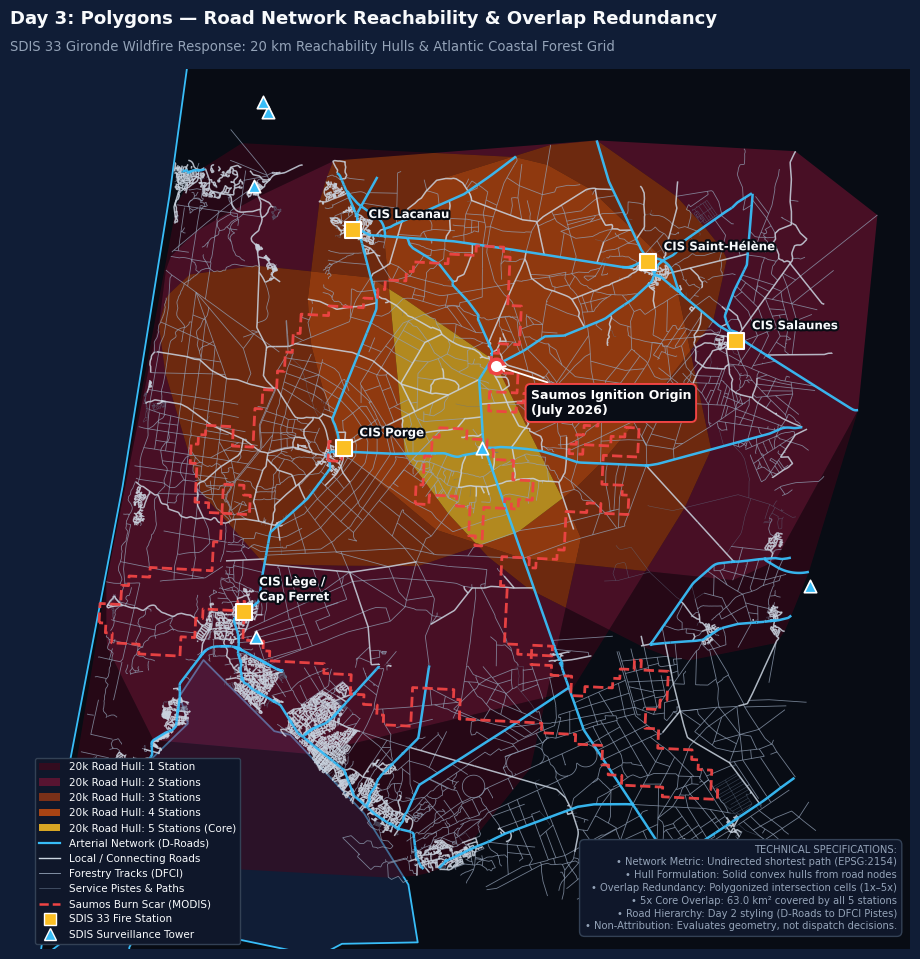

In [14]:
# Cell Nr: 007 - Master Production Map: Square 1:1 Canvas (10, 10) for LinkedIn

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
import geopandas as gpd

# 0. Ensure Day 2 Road Classification is applied to gdf_roads
def classify_road_day2(row):
    hw = row.get("highway", "")
    if isinstance(hw, list):
        hw = hw[0] if hw else ""
    hw = str(hw).lower()
    if hw in ["primary", "secondary", "primary_link", "secondary_link"]:
        return "1. Arterial / Regional (D-Roads)"
    elif hw in ["tertiary", "unclassified", "residential", "tertiary_link"]:
        return "2. Local / Connecting Roads"
    elif hw == "track":
        return "3. Forest Tracks & Fire Access"
    elif hw in ["service", "path", "cycleway", "footway"]:
        return "4. Service Pistes & Paths"
    return "5. Other"

if "gdf_roads" in locals() and "road_class" not in gdf_roads.columns:
    gdf_roads["road_class"] = gdf_roads.apply(classify_road_day2, axis=1)

# Compact station callsigns (removes long administrative prefixes)
def clean_station_name(name):
    name = name.replace("Centre d'incendie et de secours de ", "CIS ")
    name = name.replace("Centre d'incendie et de secours du ", "CIS ")
    name = name.replace("Centre d'incendie et de secours d'", "CIS ")
    name = name.replace("Centre d'incendie et de secours ", "CIS ")
    if "Lège" in name:
        return "CIS Lège /\nCap Ferret"
    return name

# Color palette: Atlantic Ocean vs. Dark Forest Mainland
ocean_color    = "#101d36" # Deep navy Atlantic Ocean
mainland_color = "#080c14" # Dark forest floor
scar_red       = "#ef4444" # Bright crimson for burn perimeter
text_color     = "#f8fafc"

# Initialize exact square figure (10, 10)
fig = plt.figure(figsize=(10, 10), facecolor=ocean_color)
ax = fig.add_axes([0.04, 0.04, 0.92, 0.88], facecolor=ocean_color)

# ==============================================================================
# LAYER 0: Base Geography (Mainland Landmass & Coastal Lakes)
# ==============================================================================
if "gdf_mainland_clean" in locals() and gdf_mainland_clean is not None:
    gdf_mainland_clean.plot(
        ax=ax, facecolor=mainland_color, edgecolor="#38bdf8", linewidth=1.3, zorder=1
    )

if "gdf_lakes" in locals() and gdf_lakes is not None and not gdf_lakes.empty:
    gdf_lakes.plot(
        ax=ax, facecolor=ocean_color, edgecolor="#38bdf8", linewidth=0.8, alpha=0.95, zorder=2
    )

# ==============================================================================
# LAYER 1: 20k Overlap Redundancy Choropleth (Luminous Heat Progression)
# ==============================================================================
overlap_palette = {
    1: "#4c0519",  # 1 station : Deep Rose Wine
    2: "#881337",  # 2 stations: Rich Crimson
    3: "#c2410c",  # 3 stations: Vivid Burnt Orange
    4: "#ea580c",  # 4 stations: Bright Flame Orange
    5: "#fbbf24"   # 5 stations: Luminous Amber/Gold Core
}
alpha_map = {1: 0.45, 2: 0.50, 3: 0.55, 4: 0.60, 5: 0.70}

for count in sorted(gdf_overlap["station_count"].unique()):
    color = overlap_palette.get(count, "#fbbf24")
    sub_gdf = gdf_overlap[gdf_overlap["station_count"] == count]
    if not sub_gdf.empty:
        sub_gdf.plot(
            ax=ax,
            facecolor=color,
            edgecolor="none",
            alpha=alpha_map.get(count, 0.60),
            zorder=3 + count * 0.05
        )

# ==============================================================================
# LAYER 2: Day 2 Road Hierarchy (Drawn ON TOP of the polygons)
# ==============================================================================
road_styles_day2 = {
    "4. Service Pistes & Paths":        {"color": "#64748b", "lw": 0.40, "alpha": 0.55, "zorder": 4},
    "3. Forest Tracks & Fire Access":  {"color": "#94a3b8", "lw": 0.60, "alpha": 0.75, "zorder": 5},
    "2. Local / Connecting Roads":      {"color": "#cbd5e1", "lw": 1.10, "alpha": 0.85, "zorder": 6},
    "1. Arterial / Regional (D-Roads)": {"color": "#38bdf8", "lw": 1.80, "alpha": 0.95, "zorder": 7}
}

if "gdf_roads" in locals() and "road_class" in gdf_roads.columns:
    for r_class, style in road_styles_day2.items():
        subset = gdf_roads[gdf_roads["road_class"] == r_class]
        if not subset.empty:
            subset.plot(
                ax=ax,
                color=style["color"],
                linewidth=style["lw"],
                alpha=style["alpha"],
                zorder=style["zorder"]
            )

# ==============================================================================
# LAYER 3: Saumos Wildfire Burn Scar (Red Dashed Line, No Fill)
# ==============================================================================
gdf_main_burn.plot(
    ax=ax,
    facecolor="none",
    edgecolor=scar_red,
    linestyle="--",
    linewidth=2.0,
    alpha=0.95,
    zorder=8
)

# ==============================================================================
# LAYER 4: Points & Labels (Drawn ON TOP of all road and boundary lines)
# ==============================================================================
# 1. SDIS 33 Surveillance Towers
for _, tow in gdf_towers.iterrows():
    ax.scatter(
        [tow.geometry.x], [tow.geometry.y],
        marker="^", color="#38bdf8", edgecolor="#ffffff",
        s=80, linewidth=1.2, zorder=9
    )

# 2. SDIS 33 Fire Stations (with compact CIS callsigns)
for _, st in gdf_active_stations.iterrows():
    pt = st.geometry
    ax.scatter(
        [pt.x], [pt.y],
        marker="s", color="#fbbf24", edgecolor="#ffffff",
        s=120, linewidth=1.5, zorder=10
    )
    ax.annotate(
        clean_station_name(st["name"]),
        xy=(pt.x, pt.y),
        xytext=(pt.x + 800, pt.y + 600),
        fontsize=8.5, fontweight="bold", color="#f8fafc",
        path_effects=[pe.withStroke(linewidth=3, foreground="#080c14")],
        zorder=12
    )

# 3. Saumos Ground-Truth Ignition Origin (with Solid Opaque Callout Badge)
ax.scatter([target_pt.x], [target_pt.y], color="#ffffff", edgecolor=scar_red, s=110, linewidth=2.5, zorder=15)
ax.annotate(
    "Saumos Ignition Origin\n(July 2026)",
    xy=(target_pt.x, target_pt.y),
    xytext=(target_pt.x + 1800, target_pt.y - 2500),
    fontsize=9.0, fontweight="bold", color="#ffffff",
    bbox=dict(boxstyle="round,pad=0.40", facecolor="#090d16", edgecolor=scar_red, linewidth=1.4, alpha=1.0),
    arrowprops=dict(arrowstyle="->", color="#ffffff", lw=1.3),
    zorder=20
)

# ==============================================================================
# VIEWPORT & AXIS FRAMING (Exact 1:1 Square Extent)
# ==============================================================================
active_geoms = list(hulls_20k) + list(gdf_active_stations.geometry) + [target_pt, gdf_main_burn.geometry.iloc[0]]
bounds = gpd.GeoSeries(active_geoms, crs="EPSG:2154").total_bounds
cx = (bounds[0] + bounds[2]) / 2.0
cy = (bounds[1] + bounds[3]) / 2.0
span = max(bounds[2] - bounds[0], bounds[3] - bounds[1]) * 1.08

ax.set_xlim(cx - span / 2.0, cx + span / 2.0)
ax.set_ylim(cy - span / 2.0, cy + span / 2.0)
ax.set_axis_off()

# Clean Square Headers
fig.text(0.04, 0.965, "Day 3: Polygons — Road Network Reachability & Overlap Redundancy", fontsize=13, fontweight="bold", color=text_color, ha="left")
fig.text(0.04, 0.938, "SDIS 33 Gironde Wildfire Response: 20 km Reachability Hulls & Atlantic Coastal Forest Grid", fontsize=9.5, color="#94a3b8", ha="left")

# Custom Legend
legend_elements = [
    # Redundancy Polygons
    mpatches.Patch(facecolor="#4c0519", alpha=0.6, label="20k Road Hull: 1 Station"),
    mpatches.Patch(facecolor="#881337", alpha=0.6, label="20k Road Hull: 2 Stations"),
    mpatches.Patch(facecolor="#c2410c", alpha=0.6, label="20k Road Hull: 3 Stations"),
    mpatches.Patch(facecolor="#ea580c", alpha=0.7, label="20k Road Hull: 4 Stations"),
    mpatches.Patch(facecolor="#fbbf24", alpha=0.85, label="20k Road Hull: 5 Stations (Core)"),
    # Day 2 Road Hierarchy
    plt.Line2D([0], [0], color="#38bdf8", lw=1.6, label="Arterial Network (D-Roads)"),
    plt.Line2D([0], [0], color="#cbd5e1", lw=1.0, label="Local / Connecting Roads"),
    plt.Line2D([0], [0], color="#94a3b8", lw=0.6, label="Forestry Tracks (DFCI)"),
    plt.Line2D([0], [0], color="#64748b", lw=0.4, label="Service Pistes & Paths"),
    # Geography, Perimeters & Points
    plt.Line2D([0], [0], color=scar_red, linestyle="--", linewidth=1.8, label="Saumos Burn Scar (MODIS)"),
    plt.Line2D([0], [0], marker="s", color="none", markeredgecolor="#ffffff", markerfacecolor="#fbbf24", markersize=9, label="SDIS 33 Fire Station"),
    plt.Line2D([0], [0], marker="^", color="none", markeredgecolor="#ffffff", markerfacecolor="#38bdf8", markersize=8, label="SDIS Surveillance Tower")
]

leg = ax.legend(
    handles=legend_elements, loc="lower left", facecolor="#0f172a", edgecolor="#334155",
    fontsize=7.5, framealpha=1.0, labelcolor=text_color
)
leg.get_frame().set_linewidth(1.0)
leg.set_zorder(100)

# Compact Technical Specs Box (fits neatly inside right margin)
specs_text = (
    "TECHNICAL SPECIFICATIONS:\n"
    "• Network Metric: Undirected shortest path (EPSG:2154)\n"
    "• Hull Formulation: Solid convex hulls from road nodes\n"
    "• Overlap Redundancy: Polygonized intersection cells (1x–5x)\n"
    "• 5x Core Overlap: 63.0 km² covered by all 5 stations\n"
    "• Road Hierarchy: Day 2 styling (D-Roads to DFCI Pistes)\n"
    "• Non-Attribution: Evaluates geometry, not dispatch decisions."
)
ax.text(
    0.985, 0.02, specs_text,
    transform=ax.transAxes, ha="right", va="bottom",
    fontsize=7.2, color="#94a3b8", linespacing=1.35,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#0f172a", edgecolor="#334155", alpha=1.0),
    zorder=100
)

output_map = "fire_polygons_final.png"
fig.savefig(output_map, dpi=300, facecolor=ocean_color)
print(f"\nSuccessfully exported square production map (3000x3000 px) to: {output_map}")
plt.show()
